# Flat Black–Scholes benchmark  
## Dumas Model 0-inspired implementation

This notebook estimates one constant volatility for each daily option cross-section.

The daily volatility is selected to minimise squared **dollar price errors**:

$$
\widehat{\sigma}_t
=
\arg\min_{\sigma}
\sum_{i\in\mathcal C_t}
\left(
C_i^{BS}(\sigma)-C_i^{market}
\right)^2.
$$

This corresponds to the central idea of Dumas, Fleming and Whaley's **Model 0**: every option in a cross-section is forced to share one volatility.

Two adaptations should be kept explicit:

1. the notebook uses observed IvyDB spot, forward and zero-curve inputs rather than jointly inferring the index level;
2. the prediction and hedge horizon is one trading day rather than the paper's one week.

The notebook is separate from the ad hoc BS smoother. Flat BS has one volatility per date; the ad hoc model allows fitted implied volatility to vary across moneyness and maturity.

# Shared IvyDB preparation for the SPX benchmarks

This notebook uses the same deliberately small data pipeline as the other benchmark notebook.

The common market universe is called `quotes_all`. It keeps both ITM and OTM options. OTM selection is **not** a permanent cleaning rule.

A second table, `calibration_quotes`, is used to calibrate the model. Its default is OTM-only because:

- OTM options usually have more reliable time value and implied volatility;
- using both an ITM option and its OTM put–call-parity counterpart adds largely repeated information;
- local-volatility, Heston and neural-SDE calibrations can later use the same OTM calibration universe.

The final evaluation table is built from `quotes_all`, so pricing and hedging can still be reported over the wider clean universe.

For later model comparisons, retain the identifier

```text
pair_id = date | date_next | optionid
```

and compare models only on the intersection of their available `pair_id` values.

## 1. Imports, filenames and a few visible choices

The settings below are intentionally limited. They determine the common sample and should remain unchanged across flat BS, ad hoc BS, local volatility, Heston and neural SDE.

In [18]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import brentq, minimize_scalar
from scipy.stats import norm

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 160)

DATA_FOLDER = Path(".")

OPTIONS_FILE = DATA_FOLDER / "one_month_spx_option_price.csv"
SPOT_FILE = DATA_FOLDER / "one_month_spx_security_price.csv"
FORWARD_FILE = DATA_FOLDER / "one_month_spx_forward_price.csv"
RATE_FILE = DATA_FOLDER / "one_month_spx_zero_coupon_yield_curve.csv"

TARGET_SECID = 108105

MIN_DTE = 14
MAX_DTE = 365
MAX_ABS_LOG_MONEYNESS = 0.30
MAX_RELATIVE_SPREAD = 0.50

# OTM-only calibration is a modelling choice
CALIBRATE_ON_OTM_ONLY = True

print("Imports and settings completed.")

Imports and settings completed.


## 2. Load the four raw CSV files

Each table has one role:

- `options_raw`: SPX option quotes;
- `spot_raw`: the daily SPX index level;
- `forwards_raw`: the forward index level for each expiry and settlement convention;
- `rates_raw`: the zero-coupon curve for each quote date.

Security Name History is not needed after confirming that SPX has `secid = 108105`.

In [19]:
options_raw = pd.read_csv(OPTIONS_FILE, low_memory=False)
spot_raw = pd.read_csv(SPOT_FILE)
forwards_raw = pd.read_csv(FORWARD_FILE)
rates_raw = pd.read_csv(RATE_FILE)

print("Raw shapes")
print("options: ", options_raw.shape)
print("spot:    ", spot_raw.shape)
print("forwards:", forwards_raw.shape)
print("rates:   ", rates_raw.shape)

Raw shapes
options:  (326964, 27)
spot:     (20, 7)
forwards: (1192, 7)
rates:    (220, 3)


## 3. Basic option cleaning

This block performs only the cleaning needed for a valid common benchmark:

1. parse dates and numeric columns;
2. divide IvyDB `strike_price` by 1,000;
3. construct midpoint and spread;
4. retain standard European SPX contracts;
5. remove invalid or very wide quotes;
6. retain 14–365 days to expiry.

The standard SPX contract multiplier is **100**. The separate factor of **1,000** applies only to IvyDB's stored strike.

In [20]:
options = options_raw.copy()

# The Option Prices table contains a forward_price column in this download,
# but it is entirely missing. The separate Forward Price table is used below.
if "forward_price" in options.columns:
    options = options.drop(columns=["forward_price"])

options["date"] = pd.to_datetime(options["date"], errors="coerce")
options["exdate"] = pd.to_datetime(options["exdate"], errors="coerce")

numeric_columns = [
    "secid",
    "strike_price",
    "best_bid",
    "best_offer",
    "impl_volatility",
    "delta",
    "vega",
    "optionid",
    "am_settlement",
    "contract_size",
]

for column in numeric_columns:
    if column in options.columns:
        options[column] = pd.to_numeric(options[column], errors="coerce")

options["strike"] = options["strike_price"] / 1000.0
options["mid"] = (options["best_bid"] + options["best_offer"]) / 2.0
options["spread"] = options["best_offer"] - options["best_bid"]
options["relative_spread"] = options["spread"] / options["mid"]
options["dte"] = (options["exdate"] - options["date"]).dt.days
options["T"] = options["dte"] / 365.0

standard_contract = (
    options["ss_flag"].astype(str).isin(["0", "0.0"])
    & options["contract_size"].eq(100)
)

valid_quote = (
    options["best_bid"].gt(0)
    & options["best_offer"].ge(options["best_bid"])
    & options["mid"].gt(0)
    & options["relative_spread"].le(MAX_RELATIVE_SPREAD)
)

basic_keep = (
    options["secid"].eq(TARGET_SECID)
    & options["exercise_style"].astype(str).str.upper().eq("E")
    & options["cp_flag"].isin(["C", "P"])
    & standard_contract
    & valid_quote
    & options["strike"].gt(0)
    & options["dte"].between(MIN_DTE, MAX_DTE)
)

rows_before = len(options)
options = options.loc[basic_keep].copy()

duplicate_count = options.duplicated(["optionid", "date"]).sum()
if duplicate_count > 0:
    raise ValueError(
        f"Found {duplicate_count} duplicate (optionid, date) observations. "
        "Resolve these before continuing."
    )

print(f"Rows before basic cleaning: {rows_before:,}")
print(f"Rows after basic cleaning:  {len(options):,}")

Rows before basic cleaning: 326,964
Rows after basic cleaning:  316,297


## 4. Clean and merge spot and forward prices

The merge keys are:

- spot: `(secid, date)`;
- forward: `(secid, date, exdate, am_settlement)`.

The settlement flag is essential because AM- and PM-settled SPX contracts can share the same calendar expiry.

In [21]:
spot = spot_raw.copy()
spot["date"] = pd.to_datetime(spot["date"], errors="coerce")
spot["secid"] = pd.to_numeric(spot["secid"], errors="coerce")
spot["close"] = pd.to_numeric(spot["close"], errors="coerce")

spot = (
    spot.loc[spot["secid"].eq(TARGET_SECID), ["secid", "date", "close"]]
    .rename(columns={"close": "spot"})
    .copy()
)

if spot.duplicated(["secid", "date"]).any():
    raise ValueError("Security Prices is not unique on (secid, date).")

forwards = forwards_raw.rename(
    columns={
        "expiration": "exdate",
        "AMSettlement": "am_settlement",
        "ForwardPrice": "forward_price",
    }
).copy()

forwards["date"] = pd.to_datetime(forwards["date"], errors="coerce")
forwards["exdate"] = pd.to_datetime(forwards["exdate"], errors="coerce")
forwards["secid"] = pd.to_numeric(forwards["secid"], errors="coerce")
forwards["am_settlement"] = pd.to_numeric(
    forwards["am_settlement"], errors="coerce"
)
forwards["forward_price"] = pd.to_numeric(
    forwards["forward_price"], errors="coerce"
)

forwards = forwards.loc[
    forwards["secid"].eq(TARGET_SECID),
    ["secid", "date", "exdate", "am_settlement", "forward_price"],
].copy()

forward_key = ["secid", "date", "exdate", "am_settlement"]

if forwards.duplicated(forward_key).any():
    raise ValueError(
        "Forward Prices is not unique after including AM settlement."
    )

options = options.merge(
    spot,
    on=["secid", "date"],
    how="left",
    validate="many_to_one",
)

options = options.merge(
    forwards,
    on=forward_key,
    how="left",
    validate="many_to_one",
)

print("Missing spot values:   ", options["spot"].isna().sum())
print("Missing forward values:", options["forward_price"].isna().sum())

Missing spot values:    0
Missing forward values: 0


## 5. Interpolate the zero rate

IvyDB supplies rates at selected maturities. For an option whose maturity lies between curve points, we linearly interpolate.

The downloaded rates are in percentage points, so `5.30` becomes `0.0530`.

This notebook treats the zero rate as continuously compounded:

$$
D(t,T)=e^{-rT}.
$$

The maturity filter keeps options inside the downloaded curve range, so the interpolation is not intended to extrapolate.

In [22]:
rates = rates_raw.copy()
rates["date"] = pd.to_datetime(rates["date"], errors="coerce")
rates["days"] = pd.to_numeric(rates["days"], errors="coerce")
rates["rate"] = pd.to_numeric(rates["rate"], errors="coerce")
rates["rate_decimal"] = rates["rate"] / 100.0

options["rate"] = np.nan

for date in options["date"].dropna().unique():
    rows_today = options["date"].eq(date)
    curve_today = rates.loc[rates["date"].eq(date)].sort_values("days")

    if curve_today.empty:
        continue

    dte_today = options.loc[rows_today, "dte"]

    inside_curve = (
        dte_today.ge(curve_today["days"].min())
        & dte_today.le(curve_today["days"].max())
    )

    valid_indices = dte_today.index[inside_curve]

    options.loc[valid_indices, "rate"] = np.interp(
        options.loc[valid_indices, "dte"],
        curve_today["days"],
        curve_today["rate_decimal"],
    )

options["discount"] = np.exp(-options["rate"] * options["T"])

print("Missing interpolated rates:", options["rate"].isna().sum())

Missing interpolated rates: 0


## 6. Final common quote universe

Forward moneyness is

$$
m=\frac{K}{F}-1,
$$

and log-forward moneyness is

$$
k=\log\left(\frac{K}{F}\right).
$$

Dumas defines moneyness using \(K/F-1\), so the Dumas ad hoc specification later uses `moneyness`.

At this stage we:

- require matched spot, forward and rate;
- keep a moderate log-moneyness range;
- remove midpoint prices outside elementary European no-arbitrage bounds;
- label OTM options without deleting ITM options.

The result, `quotes_all`, is the shared cleaned universe.

In [23]:
options = options.dropna(
    subset=[
        "date",
        "exdate",
        "optionid",
        "spot",
        "forward_price",
        "rate",
        "discount",
    ]
).copy()

options["moneyness"] = options["strike"] / options["forward_price"] - 1.0
options["log_moneyness"] = np.log(
    options["strike"] / options["forward_price"]
)

is_call = options["cp_flag"].eq("C")
is_put = options["cp_flag"].eq("P")

options["is_otm"] = (
    (is_call & options["strike"].ge(options["forward_price"]))
    | (is_put & options["strike"].lt(options["forward_price"]))
)

options["lower_bound"] = np.where(
    is_call,
    options["discount"]
    * np.maximum(options["forward_price"] - options["strike"], 0.0),
    options["discount"]
    * np.maximum(options["strike"] - options["forward_price"], 0.0),
)

options["upper_bound"] = np.where(
    is_call,
    options["discount"] * options["forward_price"],
    options["discount"] * options["strike"],
)

inside_bounds = (
    options["mid"].gt(options["lower_bound"] + 1e-10)
    & options["mid"].lt(options["upper_bound"] - 1e-10)
)

common_keep = (
    options["log_moneyness"].abs().le(MAX_ABS_LOG_MONEYNESS)
    & inside_bounds
)

quotes_all = options.loc[common_keep].copy()
quotes_all = quotes_all.sort_values(["date", "optionid"]).reset_index(drop=True)

if CALIBRATE_ON_OTM_ONLY:
    calibration_quotes = quotes_all.loc[quotes_all["is_otm"]].copy()
else:
    calibration_quotes = quotes_all.copy()

print(f"Common clean quotes: {len(quotes_all):,}")
print(f"Calibration quotes:  {len(calibration_quotes):,}")
print(f"OTM share of common quotes: {quotes_all['is_otm'].mean():.2%}")
print(f"Dates: {quotes_all['date'].nunique()}")
print(f"Contracts: {quotes_all['optionid'].nunique()}")

Common clean quotes: 243,997
Calibration quotes:  125,746
OTM share of common quotes: 51.54%
Dates: 20
Contracts: 18290


## 7. Common spread statistics

These statistics describe `quotes_all`, not a model-specific subset.

Average bid–ask spread: 3.4692
Median bid–ask spread:  0.8000
Average relative spread: 2.39%
0.500     0.8
0.750     6.6
0.900     8.6
0.950    10.8
0.995    21.1
Name: spread, dtype: float64
Min spread: 0.04999999999999982
Max spread: 72.0


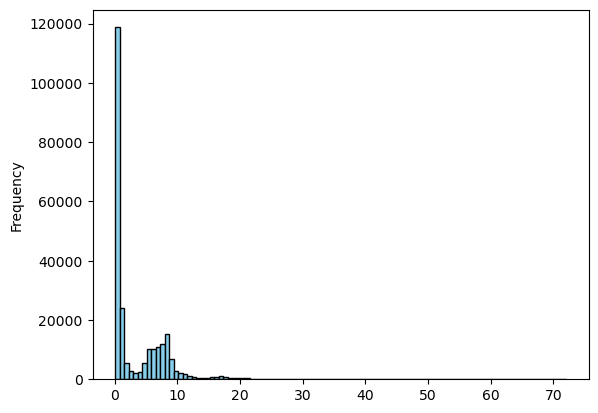

In [24]:
average_spread = quotes_all["spread"].mean()
median_spread = quotes_all["spread"].median()
average_relative_spread = quotes_all["relative_spread"].mean()

print(f"Average bid–ask spread: {average_spread:.4f}")
print(f"Median bid–ask spread:  {median_spread:.4f}")
print(f"Average relative spread: {average_relative_spread:.2%}")

# post-cleaning options

quotes_all["spread"].plot(kind="hist", bins=100, edgecolor="black", color="skyblue")
print(quotes_all["spread"].quantile([0.5, 0.75, 0.9, 0.95, 0.995]))

print("Min spread:", min(quotes_all["spread"]))
print("Max spread:", max(quotes_all["spread"]))

## 8. Black–Scholes price and delta

Both benchmark notebooks use the same forward-form Black–Scholes functions.

For a call,

$$
C=D\left(FN(d_1)-KN(d_2)\right).
$$

The spot delta is recovered from the observed relation between spot and forward:

$$
\Delta_{\mathrm{call}}=D\frac{F}{S}N(d_1).
$$

This keeps the option-pricing inputs consistent with the separate IvyDB forward table.

In [25]:
def bs_price(cp_flag, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    d2 = d1 - sigma * sqrt_T

    call = discount * (
        forward * norm.cdf(d1)
        - strike * norm.cdf(d2)
    )

    put = discount * (
        strike * norm.cdf(-d2)
        - forward * norm.cdf(-d1)
    )

    return np.where(cp_flag == "C", call, put)


def bs_delta(cp_flag, spot, forward, strike, T, discount, sigma):
    cp_flag = np.asarray(cp_flag)
    spot = np.asarray(spot, dtype=float)
    forward = np.asarray(forward, dtype=float)
    strike = np.asarray(strike, dtype=float)
    T = np.asarray(T, dtype=float)
    discount = np.asarray(discount, dtype=float)
    sigma = np.asarray(sigma, dtype=float)

    sqrt_T = np.sqrt(T)

    d1 = (
        np.log(forward / strike)
        + 0.5 * sigma**2 * T
    ) / (sigma * sqrt_T)

    carry = discount * forward / spot

    call_delta = carry * norm.cdf(d1)
    put_delta = carry * (norm.cdf(d1) - 1.0)

    return np.where(cp_flag == "C", call_delta, put_delta)

## 9. Build the common one-trading-day evaluation pairs

This step uses `quotes_all`, not `calibration_quotes`.

A quote on date \(t\) is paired with the same `optionid` on the next date in the SPX trading calendar. Reappearance after a longer gap is not treated as a one-day observation.

The resulting `evaluation_pairs` is the common candidate universe for every benchmark.

In [26]:
trading_dates = sorted(spot["date"].dropna().unique())

next_date_map = {
    trading_dates[i]: trading_dates[i + 1]
    for i in range(len(trading_dates) - 1)
}

today = quotes_all.copy()
today["date_next"] = today["date"].map(next_date_map)
today = today.dropna(subset=["date_next"]).copy()

tomorrow_columns = [
    "optionid",
    "date",
    "exdate",
    "cp_flag",
    "strike",
    "mid",
    "best_bid",
    "best_offer",
    "spot",
    "forward_price",
    "rate",
    "discount",
    "T",
    "dte",
    "moneyness",
    "log_moneyness",
    "is_otm",
]

tomorrow = quotes_all[tomorrow_columns].copy()

tomorrow = tomorrow.rename(
    columns={
        "date": "date_next",
        "exdate": "exdate_next",
        "cp_flag": "cp_flag_next",
        "strike": "strike_next",
        "mid": "mid_next",
        "best_bid": "best_bid_next",
        "best_offer": "best_offer_next",
        "spot": "spot_next",
        "forward_price": "forward_price_next",
        "rate": "rate_next",
        "discount": "discount_next",
        "T": "T_next",
        "dte": "dte_next",
        "moneyness": "moneyness_next",
        "log_moneyness": "log_moneyness_next",
        "is_otm": "is_otm_next",
    }
)

evaluation_pairs = today.merge(
    tomorrow,
    on=["optionid", "date_next"],
    how="inner",
    validate="one_to_one",
)

evaluation_pairs["pair_id"] = (
    evaluation_pairs["date"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["date_next"].dt.strftime("%Y-%m-%d")
    + "|"
    + evaluation_pairs["optionid"].astype("Int64").astype(str)
)

evaluation_pairs["option_change"] = (
    evaluation_pairs["mid_next"] - evaluation_pairs["mid"]
)

print(f"Common candidate one-day pairs: {len(evaluation_pairs):,}")
print(f"Current dates represented: {evaluation_pairs['date'].nunique()}")

Common candidate one-day pairs: 224,566
Current dates represented: 19


## 10. Common metric helper

The helper reports:

- midpoint RMSE and MAE;
- proportion inside each quote's own bid–ask interval;
- average distance outside the interval;
- hedging RMSE, MAE and bias where a hedge-error column is supplied.

It does not change the data.

In [27]:
def summarise_model(
    data,
    price_error_column,
    model_price_column,
    hedge_error_column=None,
):
    price_error = data[price_error_column]

    inside_bid_ask = data[model_price_column].between(
        data["best_bid_next"],
        data["best_offer_next"],
    )

    outside_spread_error = np.maximum(
        data["best_bid_next"] - data[model_price_column],
        data[model_price_column] - data["best_offer_next"],
    )
    outside_spread_error = np.maximum(outside_spread_error, 0.0)

    result = {
        "number_of_pairs": len(data),
        "next_day_price_rmse": np.sqrt(np.mean(price_error**2)),
        "next_day_price_mae": np.mean(np.abs(price_error)),
        "next_day_inside_bid_ask": inside_bid_ask.mean(),
        "next_day_outside_spread_mae": outside_spread_error.mean(),
        "unhedged_mae": data["option_change"].abs().mean(),
    }

    if hedge_error_column is not None:
        hedge_error = data[hedge_error_column]

        result["hedging_rmse"] = np.sqrt(np.mean(hedge_error**2))
        result["hedging_mae"] = np.mean(np.abs(hedge_error))
        result["hedging_bias"] = hedge_error.mean()
        result["hedging_improvement"] = (
            1.0
            - result["hedging_mae"] / result["unhedged_mae"]
        )

    return pd.Series(result)

# Flat BS model

## 11. Fit one constant volatility per date

The calibration objective is directly in option-price space, not IV space.

`minimize_scalar` tries different positive volatility values and retains the one with the smallest mean squared pricing error on that date's `calibration_quotes`.

In [28]:
flat_rows = []

for date, daily_quotes in calibration_quotes.groupby("date"):
    if len(daily_quotes) < 10:
        continue

    cp = daily_quotes["cp_flag"].to_numpy()
    F = daily_quotes["forward_price"].to_numpy()
    K = daily_quotes["strike"].to_numpy()
    T = daily_quotes["T"].to_numpy()
    D = daily_quotes["discount"].to_numpy()
    market_price = daily_quotes["mid"].to_numpy()

    def price_loss(sigma):
        model_price = bs_price(cp, F, K, T, D, sigma)
        return np.mean((model_price - market_price) ** 2)

    fit = minimize_scalar(
        price_loss,
        bounds=(0.01, 3.00),
        method="bounded",
    )

    flat_rows.append(
        {
            "date": date,
            "flat_iv": fit.x,
            "calibration_mse": fit.fun,
            "calibration_quotes": len(daily_quotes),
        }
    )

flat_parameters = pd.DataFrame(flat_rows)

print("Dates calibrated:", len(flat_parameters))
flat_parameters.head()

Dates calibrated: 20


,date,flat_iv,calibration_mse,calibration_quotes
0,2024-03-01,0.134287,240.857382,5934
1,2024-03-04,0.135748,231.388620,6205
2,2024-03-05,0.139846,239.075803,6191
3,2024-03-06,0.140107,236.538661,6156
4,2024-03-07,0.140536,222.997976,6108


## 12. Same-day price and delta on the full clean quote universe

Calibration may use OTM options only, but same-day evaluation is performed on `quotes_all`, which contains both ITM and OTM options.

In [29]:
flat_quotes = quotes_all.merge(
    flat_parameters,
    on="date",
    how="inner",
)

flat_quotes["model_price"] = bs_price(
    flat_quotes["cp_flag"],
    flat_quotes["forward_price"],
    flat_quotes["strike"],
    flat_quotes["T"],
    flat_quotes["discount"],
    flat_quotes["flat_iv"],
)

flat_quotes["model_delta"] = bs_delta(
    flat_quotes["cp_flag"],
    flat_quotes["spot"],
    flat_quotes["forward_price"],
    flat_quotes["strike"],
    flat_quotes["T"],
    flat_quotes["discount"],
    flat_quotes["flat_iv"],
)

flat_quotes["same_day_price_error"] = (
    flat_quotes["model_price"] - flat_quotes["mid"]
)

same_day_inside = flat_quotes["model_price"].between(
    flat_quotes["best_bid"],
    flat_quotes["best_offer"],
)

same_day_outside = np.maximum(
    flat_quotes["best_bid"] - flat_quotes["model_price"],
    flat_quotes["model_price"] - flat_quotes["best_offer"],
)
same_day_outside = np.maximum(same_day_outside, 0.0)

print(
    "Same-day price RMSE:",
    np.sqrt(np.mean(flat_quotes["same_day_price_error"] ** 2)),
)
print(
    "Same-day price MAE:",
    flat_quotes["same_day_price_error"].abs().mean(),
)
print("Same-day inside bid-ask:", same_day_inside.mean())
print("Same-day outside-spread MAE:", same_day_outside.mean())

Same-day price RMSE: 19.093957153234882
Same-day price MAE: 14.438469731214042
Same-day inside bid-ask: 0.039148022311749735
Same-day outside-spread MAE: 12.759424055101453


## 13. Frozen one-day-ahead price

Today's fitted constant volatility is carried forward unchanged.

Tomorrow's:

- forward;
- remaining maturity;
- discount factor;

are updated, but tomorrow's option prices are not used to recalibrate before prediction.

In [30]:
flat_pairs = evaluation_pairs.merge(
    flat_quotes[
        [
            "date",
            "optionid",
            "flat_iv",
            "model_delta",
            "model_price",
        ]
    ],
    on=["date", "optionid"],
    how="inner",
    validate="one_to_one",
)

flat_pairs["predicted_price_next"] = bs_price(
    flat_pairs["cp_flag_next"],
    flat_pairs["forward_price_next"],
    flat_pairs["strike_next"],
    flat_pairs["T_next"],
    flat_pairs["discount_next"],
    flat_pairs["flat_iv"],
)

flat_pairs["next_day_price_error"] = (
    flat_pairs["predicted_price_next"] - flat_pairs["mid_next"]
)

print(
    "Next-day price RMSE:",
    np.sqrt(np.mean(flat_pairs["next_day_price_error"] ** 2)),
)
print(
    "Next-day price MAE:",
    flat_pairs["next_day_price_error"].abs().mean(),
)

Next-day price RMSE: 19.20810692663635
Next-day price MAE: 14.508039985419177


## 14. One-day delta hedge

For a long option, the simple one-day hedge error is

$$
\varepsilon_{t+1}
=
(C_{t+1}-C_t)
-
\Delta_t(S_{t+1}-S_t).
$$

This is the common discrete hedge protocol to reuse across the later benchmarks.

It ignores one-day cash interest and transaction costs. SPX is not directly tradable, so this is a theoretical index-unit hedge; an ES- or SPY-based hedge would require a separate conversion.

In [31]:
flat_pairs["hedging_error"] = (
    flat_pairs["option_change"]
    - flat_pairs["model_delta"]
      * (flat_pairs["spot_next"] - flat_pairs["spot"])
)

flat_summary = summarise_model(
    flat_pairs,
    price_error_column="next_day_price_error",
    model_price_column="predicted_price_next",
    hedge_error_column="hedging_error",
)

flat_summary

number_of_pairs                224566.000000
next_day_price_rmse                19.208107
next_day_price_mae                 14.508040
next_day_inside_bid_ask             0.037223
next_day_outside_spread_mae        12.834763
unhedged_mae                       13.058954
hedging_rmse                        2.500030
hedging_mae                         1.882958
hedging_bias                       -0.324717
hedging_improvement                 0.855811
dtype: float64

## 15. All-option and OTM-only reporting

The primary result uses all common clean evaluation pairs. The OTM-only row is a secondary breakdown and does not redefine the model sample.

In [32]:
flat_comparison = pd.DataFrame(
    {
        "all_clean_options": summarise_model(
            flat_pairs,
            "next_day_price_error",
            "predicted_price_next",
            "hedging_error",
        ),
        "otm_only": summarise_model(
            flat_pairs.loc[flat_pairs["is_otm"]],
            "next_day_price_error",
            "predicted_price_next",
            "hedging_error",
        ),
    }
).T

flat_comparison

,number_of_pairs,next_day_price_rmse,next_day_price_mae,next_day_inside_bid_ask,next_day_outside_spread_mae,unhedged_mae,hedging_rmse,hedging_mae,hedging_bias,hedging_improvement
all_clean_options,224566.0,19.208107,14.508040,0.037223,12.834763,13.058954,2.500030,1.882958,-0.324717,0.855811
otm_only,115993.0,15.560384,11.490637,0.007992,11.251687,4.568611,1.624944,1.188209,-0.209176,0.739919


## 16. Save outputs for later intersection

`flat_bs_pair_results.csv` contains `pair_id`. Later, intersect this column with the corresponding result files from ad hoc BS, LV, Heston and neural SDE before comparing metrics.

In [33]:
output_folder = Path("flat_bs_outputs")
output_folder.mkdir(exist_ok=True)

flat_parameters.to_csv(
    output_folder / "flat_bs_daily_parameters.csv",
    index=False,
)

flat_pairs.to_csv(
    output_folder / "flat_bs_pair_results.csv",
    index=False,
)

flat_comparison.to_csv(
    output_folder / "flat_bs_summary.csv",
)

evaluation_pairs[["pair_id", "date", "date_next", "optionid"]].to_csv(
    output_folder / "common_candidate_pair_keys.csv",
    index=False,
)

print("Saved outputs to:", output_folder.resolve())

Saved outputs to: C:\Users\Startklar\ICL\NDEs\Codes\BS-IVF\flat_bs_outputs


## Interpretation

Flat BS is intentionally misspecified: it cannot represent the SPX volatility skew or term structure.

Its value as a benchmark is its stability, transparency and low parameter count. Dumas, Fleming and Whaley found that this simple model hedged surprisingly well relative to their more elaborate deterministic-volatility specifications.

The model should therefore be judged separately on:

- same-day pricing;
- frozen next-day pricing;
- one-day hedge error.